# Section 4.4

# Accountability Diffusion

## Objective

Evaluate how different decision thresholds influence automated allocation decisions and illustrate how responsibility may become diffused when governance relies on algorithmic probability thresholds.

## Research Question

How do changes in allocation thresholds affect governance decisions, and what do these changes reveal about accountability within automated decision-making systems?

## Theory Link

This experiment operationalises Section 4.4 of the paper.

Accountability Diffusion occurs when responsibility for decisions becomes obscured because allocation outcomes depend primarily on algorithmic thresholds rather than transparent human judgement.

## Dataset Description

The Heart Disease Prediction Dataset is used to simulate automated allocation decisions based on predicted probabilities generated by a Logistic Regression model.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
#Import
from src.utils import load_data

from src.preprocessing import (
    encode_categorical_variables,
    split_features_target,
)

from src.modelling import (
    split_train_test,
    train_logistic_regression,
    predict_model,
)

from src.allocation import (
    simulate_allocation,
    create_allocation_summary,
    threshold_sensitivity_analysis,
    plot_allocation_simulation,
)

from src.config import (
    HEART_DATA_PATH,
    FIGURES_DIR,
)

In [3]:
#Configuration
RANDOM_STATE = 42

In [4]:
#Load Dataset
df = load_data(
    HEART_DATA_PATH
)

In [5]:
#Data Audit
print(df.shape)

df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Preprocessing

In [6]:
#Preprocessing
encoded_df = encode_categorical_variables(
    df
)

X, y = split_features_target(
    encoded_df,
    "HeartDisease",
)

X_train, X_test, y_train, y_test = split_train_test(
    X,
    y,
)

## Experiment

In [7]:
#Train Model
model = train_logistic_regression(
    X_train,
    y_train,
)

y_pred, y_prob = predict_model(
    model,
    X_test,
)

In [8]:
#Simulate Allocation
allocations = simulate_allocation(
    y_prob,
    threshold=0.50,
)

allocation_summary = create_allocation_summary(
    allocations
)

allocation_summary

,Outcome,Count
0,Allocated,109
1,Not Allocated,75


In [9]:
#Threshold Sensitivity
threshold_table = threshold_sensitivity_analysis(
    y_prob,
    thresholds=[0.30, 0.50, 0.70],
)

threshold_table

,Threshold,Allocated,Not Allocated
0,0.3,116,68
1,0.5,109,75
2,0.7,88,96


## Results

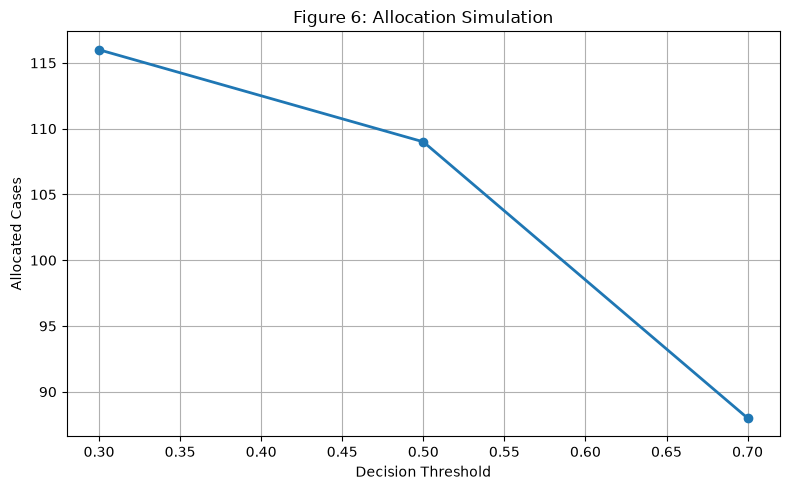

In [10]:
#Figure 6
plot_allocation_simulation(
    threshold_table,
    FIGURES_DIR / "figure_6_allocation_simulation.png",
)

In [11]:
#Allocation Summary
allocation_summary

,Outcome,Count
0,Allocated,109
1,Not Allocated,75


In [12]:
#Threshold Summary
threshold_table

,Threshold,Allocated,Not Allocated
0,0.3,116,68
1,0.5,109,75
2,0.7,88,96


In [13]:
from src.allocation import (
    create_allocation_metrics_table,
    interpret_accountability_diffusion,
)

allocation_metrics = create_allocation_metrics_table(
    threshold_table
)

allocation_metrics

,Threshold,Allocated,Not Allocated,Allocation Rate
0,0.3,116,68,0.630
1,0.5,109,75,0.592
2,0.7,88,96,0.478


In [14]:
#Interpretation Cell
interpretation = interpret_accountability_diffusion(
    allocation_metrics
)

print(interpretation)

As the allocation threshold increased from 0.30 to 0.70, the number of allocated cases decreased from 116 to 88. This demonstrates how governance rules embedded within automated decision systems influence resource allocation decisions, illustrating the Accountability Diffusion mechanism described in Section 4.4.


## Save Outputs

In [ ]:
from src.config import TABLES_DIR

allocation_metrics.to_csv(
    TABLES_DIR / "table_6_allocation_metrics.csv",
    index=False,
)

: 

## Conclusion

This experiment simulated allocation decisions using predicted probabilities generated by the Logistic Regression model.

Threshold sensitivity analysis demonstrated that increasing decision thresholds progressively reduced the number of individuals receiving positive allocation outcomes. These findings illustrate how governance parameters embedded within automated decision systems directly influence resource allocation and accountability.

The generated allocation metrics and visualisations provide empirical evidence supporting the Accountability Diffusion mechanism described in Section 4.4. All outputs have been automatically saved for inclusion in the publication and the interactive governance dashboard.